# 2. Paraphrase generation: rule-based vs back-translation vs T5 (RQ3)

Run notebook 1 first: this notebook reads **qqp_test.csv** from the results folder.

* **Rule-based**: WordNet synonym substitution (NLTK).
* **Back-translation**: English to German to English with MarianMT.
* **T5**: a pretrained T5 paraphrase model used as is.

In [1]:
# !pip install -q transformers sentencepiece sacremoses bert-score sentence-transformers nltk

In [2]:
import os, re, random
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROJECT_DIR = r"C:\Users\thiga\OneDrive\Documents\Masters - Big Data\Year 1\Semester 2\COS 802\Project"
OUT = os.path.join(PROJECT_DIR, "results")

if not os.path.isdir(PROJECT_DIR):
    raise FileNotFoundError(f"Project folder not found: {PROJECT_DIR}. Check the path.")

os.makedirs(OUT, exist_ok=True)
print("Saving to:", OUT)

Saving to: C:\Users\thiga\OneDrive\Documents\Masters - Big Data\Year 1\Semester 2\COS 802\Project\results


In [3]:
import matplotlib.pyplot as plt

COLORS = ["seagreen", "dodgerblue", "darkorange"]

def style(ax, grid="y"):

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(False)
    ax.tick_params(axis="both", direction="in", length=4, width=0.8)


def save_fig(name):

    plt.tight_layout()
    plt.savefig(f"{OUT}/{name}.png", dpi=300, bbox_inches="tight")

## Sample of 120 sentences

In [4]:
N_SENTENCES = 120

pool = pd.read_csv(f"{OUT}/qqp_test.csv").sentence1.drop_duplicates()
pool = pool[pool.str.split().str.len().between(6, 25)]

sentences = pool.sample(N_SENTENCES, random_state=SEED).tolist()
print(len(sentences), "sentences. Example:", sentences[0])

120 sentences. Example: I am a btech 3rd year student with 3 backs(cleared)and aggregate of 62.5%,am I eligible for placements,will I withstand filtering with such less %?


## Method 1: rule-based WordNet substitution
Replaces up to three nouns, adjectives, adverbs or base-form verbs with the first WordNet synonym found.

In [5]:
import re
import nltk

from nltk import pos_tag
from nltk.corpus import wordnet as wn

# NLTK resources
packages = ["wordnet", "omw-1.4", "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]

for package in packages:
    nltk.download(package, quiet=True)


# Word types eligible for synonym replacement
POS_MAP = {
    "NN": wn.NOUN,    # Singular nouns
    "JJ": wn.ADJ,     # Adjectives
    "RB": wn.ADV,     # Adverbs
    "VB": wn.VERB}     # Base-form verbs

MAX_SWAPS = 3


# Find the first suitable WordNet synonym
def first_synonym(word, wordnet_pos):

    # Search the first two WordNet meanings of the word
    synsets = wn.synsets(word.lower(), pos=wordnet_pos)[:2]

    for synset in synsets:

        # Check the synonyms associated with each meaning
        for lemma in synset.lemmas():

            name = lemma.name()

            # Only accept a different, single word synonym
            if name.lower() != word.lower() and "_" not in name:
                return name

    return None


# Generate a paraphrase by replacing selected words with synonyms
def wordnet_paraphrase(sentence):

    # Find every word and punctuation mark, remembering where it sits in the sentence
    matches = list(re.finditer(r"\w+(?:'\w+)?|[^\w\s]", sentence))

    # Identify the grammatical role of each token
    tagged_tokens = pos_tag([m.group() for m in matches])

    pieces = []      
    last_end = 0    
    swaps = 0

    for match, (token, tag) in zip(matches, tagged_tokens):

        synonym = None

        # Check whether the word is eligible for replacement
        if swaps < MAX_SWAPS and tag in POS_MAP and len(token) > 3 and token.isalpha():


            synonym = first_synonym(token, POS_MAP[tag])

        # Replace the word if a synonym was found
        if synonym:

            swaps += 1

            # Copy the original text up to this word
            pieces.append(sentence[last_end:match.start()])

            if token[0].isupper():
                pieces.append(synonym.capitalize())
            else:
                pieces.append(synonym)

            last_end = match.end()

    # Copy the rest of the original sentence
    pieces.append(sentence[last_end:])

    return "".join(pieces)


rule_based = []

for sentence in sentences:
    paraphrase = wordnet_paraphrase(sentence)
    rule_based.append(paraphrase)


list(zip(sentences[:3], rule_based[:3]))

[('I am a btech 3rd year student with 3 backs(cleared)and aggregate of 62.5%,am I eligible for placements,will I withstand filtering with such less %?',
  'I am a btech 3rd twelvemonth pupil with 3 backs(cleared)and sum of 62.5%,am I eligible for placements,will I withstand filtering with such less %?'),
 ('How do I know if someone is a sociopath or an introvert?',
  'How do I cognize if person is a psychopath or an introvert?'),
 ('What do you think about decision by the Indian Government to demonetise 500 and 1000 rupees note?',
  'What do you believe about determination by the Amerind Government to demonetise 500 and 1000 rupees note?')]

## Methods 2 and 3: back-translation (MarianMT) and T5

In [6]:
import torch
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# Use the GPU if available, otherwise use the CPU
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)


# Load a pretrained text-to-text model and its tokenizer
def load_seq2seq(name):

    tok = AutoTokenizer.from_pretrained(name)

    model = AutoModelForSeq2SeqLM.from_pretrained(name)
    model = model.to(device)

    model.eval()

    return tok, model


def run_seq2seq(texts, tok, model, prefix="", batch_size=16, **generate_options):

    outputs = []

    for i in tqdm(range(0, len(texts), batch_size)):

        batch = texts[i:i + batch_size]

        batch = [prefix + text for text in batch]

        # Convert sentences into model inputs
        encoded = tok(batch, return_tensors="pt", padding=True, truncation=True, max_length=128)

        encoded = encoded.to(device)

        with torch.no_grad():
            generated = model.generate(**encoded, max_length=128, **generate_options)

        # Convert generated tokens back into text
        decoded = tok.batch_decode(generated, skip_special_tokens=True)

        outputs.extend(decoded)

    return outputs


# METHOD 2: BACK-TRANSLATION

# English to German and back
en_de = load_seq2seq("Helsinki-NLP/opus-mt-en-de")
de_en = load_seq2seq("Helsinki-NLP/opus-mt-de-en")

german = run_seq2seq(sentences, *en_de, num_beams=4)
back_translated = run_seq2seq(german, *de_en, num_beams=4)


# METHOD 3: T5 PARAPHRASING

# Pretrained T5 paraphrasing model
t5 = load_seq2seq("humarin/chatgpt_paraphraser_on_T5_base")

t5_paraphrases = run_seq2seq(sentences, *t5, prefix="paraphrase: ", num_beams=5, no_repeat_ngram_size=2)

for i in range(3):

    print(f"\nSOURCE : {sentences[i]}")
    print(f"RULE   : {rule_based[i]}")
    print(f"BACK-TR: {back_translated[i]}")
    print(f"T5     : {t5_paraphrases[i]}")

Device: cuda


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]


SOURCE : I am a btech 3rd year student with 3 backs(cleared)and aggregate of 62.5%,am I eligible for placements,will I withstand filtering with such less %?
RULE   : I am a btech 3rd twelvemonth pupil with 3 backs(cleared)and sum of 62.5%,am I eligible for placements,will I withstand filtering with such less %?
BACK-TR: I am a Btech 3rd year student with 3 backs (cleared) and aggregate of 62.5%,am I for internships, will I withstand the filtering with so less %?
T5     : With 3 cleared backs and an aggregate of 62.5%, am I eligible for placements as a 3rd year btech student?

SOURCE : How do I know if someone is a sociopath or an introvert?
RULE   : How do I cognize if person is a psychopath or an introvert?
BACK-TR: How do I know if someone's a sociopath or an introvert?
T5     : What are the signs that someone is a sociopath versus an introvert?

SOURCE : What do you think about decision by the Indian Government to demonetise 500 and 1000 rupees note?
RULE   : What do you believe ab

## Scoring
* **Meaning preservation**: BERTScore F1 and sentence embedding cosine similarity between each source sentence and its paraphrase.
* **Diversity**: 1 minus the word overlap (Jaccard) between the source and the paraphrase. Higher means more different wording.
* **Balance**: The harmonic mean of cosine similarity and diversity, so a method only scores well if it both keeps the meaning and changes the words.

In [7]:
from bert_score import score as bert_score
from sentence_transformers import SentenceTransformer, util
from nltk.metrics.distance import jaccard_distance

embedder = SentenceTransformer("all-MiniLM-L6-v2")

def words(sentence):

    tokens = re.findall(r"\w+", sentence.lower())

    return set(tokens)


def score_method(method, paraphrases):

    _, _, bertscore_f1 = bert_score(
        paraphrases,
        sentences,
        lang="en",
        verbose=False)

    # Sentence embeddings
    original_emb = embedder.encode(sentences, convert_to_tensor=True)
    paraphrase_emb = embedder.encode(paraphrases, convert_to_tensor=True)

    cosine = util.pairwise_cos_sim(original_emb, paraphrase_emb).cpu().numpy()

    # Lexical diversity (Jaccard)
    diversity = [jaccard_distance(words(original), words(paraphrase))
                 for original, paraphrase in zip(sentences, paraphrases)]

    results_df = pd.DataFrame({
        "method": method,
        "source": sentences,
        "paraphrase": paraphrases,
        "bertscore_f1": bertscore_f1.numpy(),
        "cosine": cosine,
        "diversity": diversity})

    return results_df


rule_scores = score_method("Rule-based (WordNet)", rule_based)
back_scores = score_method("Back-translation", back_translated)
t5_scores = score_method("T5", t5_paraphrases)

all_rows = pd.concat(
    [rule_scores, back_scores, t5_scores],
    ignore_index=True)

all_rows.to_csv(f"{OUT}/generated_paraphrases.csv", index=False)

display(all_rows.head())

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,method,source,paraphrase,bertscore_f1,cosine,diversity
0,Rule-based (WordNet),I am a btech 3rd year student with 3 backs(cle...,I am a btech 3rd twelvemonth pupil with 3 back...,0.972853,0.927876,0.222222
1,Rule-based (WordNet),How do I know if someone is a sociopath or an ...,How do I cognize if person is a psychopath or ...,0.965192,0.845420,0.400000
2,Rule-based (WordNet),What do you think about decision by the Indian...,What do you believe about determination by the...,0.964861,0.880619,0.300000
3,Rule-based (WordNet),How do I know if an Android device is running ...,How do I cognize if an Android device is runni...,0.974864,0.957066,0.133333
4,Rule-based (WordNet),How do I improve presence of mind?,How do I better front of head?,0.913759,0.428636,0.600000


In [8]:
METHODS = ["Rule-based (WordNet)", "Back-translation", "T5"]

# Average evaluation metrics for each method
summary = all_rows.groupby("method").agg(
    bertscore_f1=("bertscore_f1", "mean"),
    cosine=("cosine", "mean"),
    diversity=("diversity", "mean"),
    unchanged=("diversity", lambda x: (x == 0).mean()))

summary = summary.loc[METHODS]

# Balance score
summary["balance"] = (2 * summary["cosine"] * summary["diversity"] / (summary["cosine"] + summary["diversity"]))

summary.to_csv(f"{OUT}/generation_results.csv")

display(summary.round(3))

,bertscore_f1,cosine,diversity,unchanged,balance
method,,,,,
Rule-based (WordNet),0.969,0.850,0.267,0.133,0.406
Back-translation,0.982,0.962,0.199,0.325,0.330
T5,0.947,0.867,0.628,0.000,0.728


### Comparison chart (RQ3)

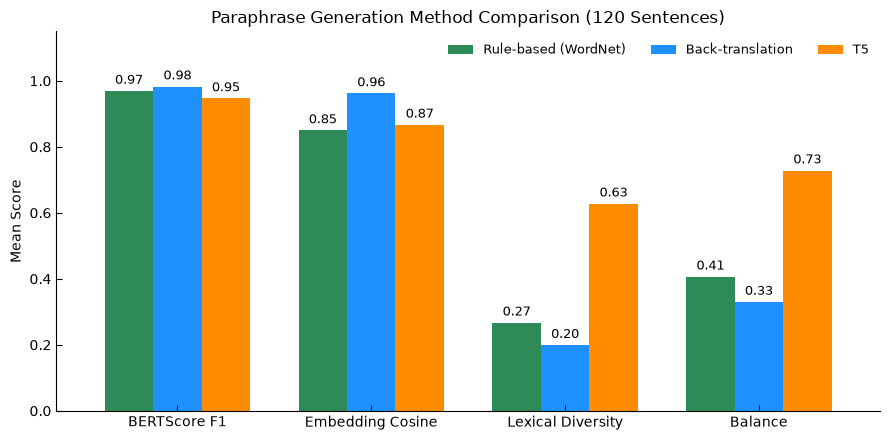

In [9]:
metrics = ["bertscore_f1", "cosine", "diversity", "balance"]

metric_names = ["BERTScore F1", "Embedding Cosine", "Lexical Diversity", "Balance"]

fig, ax = plt.subplots(figsize=(9, 4.5))

summary[metrics].T.plot(kind="bar", ax=ax, color=COLORS, width=0.75, rot=0)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)

ax.set_xticklabels(metric_names)
ax.set_ylabel("Mean Score")
ax.set_xlabel("")
ax.set_title("Paraphrase Generation Method Comparison (120 Sentences)")

ax.set_ylim(0, 1.15)
ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])

style(ax)

ax.legend(loc="upper right", frameon=False, title="", ncol=3, fontsize=9)

save_fig("fig_generation_comparison")
plt.show()
plt.close(fig)

## Manual review sheet
15 random pairs per method (45 in total). Open **manual_review_sheet.csv**, rate each pair from 1 to 5 for meaning preservation, fluency and diversity.

If the sheet already contains ratings it will not be changed.

In [10]:
RATING_COLS = ["meaning_1to5", "fluency_1to5", "diversity_1to5"]

sheet_path = f"{OUT}/manual_review_sheet.csv"


already_rated = False

if os.path.exists(sheet_path):

    existing_sheet = pd.read_csv(sheet_path, encoding="utf-8-sig")
    already_rated = existing_sheet[RATING_COLS].notna().any().any()


if already_rated:

    print("Ratings already found.")

else:

    review = all_rows.groupby("method").sample(15, random_state=SEED)

    review = review.sample(frac=1, random_state=SEED)

    review = review[["source", "paraphrase", "method"]].copy()

    for col in RATING_COLS:
        review[col] = ""

    review.to_csv(sheet_path, index=False, encoding="utf-8-sig")

    print(len(review), "pairs saved to manual_review_sheet.csv")

45 pairs saved to manual_review_sheet.csv


### Manual review results
Run this cell **after** manually rating the sheet. It averages the ratings per method (1 = poor, 5 = excellent).

,pairs_rated,meaning_1to5,fluency_1to5,diversity_1to5
method,,,,
Rule-based (WordNet),15,2.73,2.87,2.73
Back-translation,15,4.73,4.60,1.67
T5,15,4.53,5.00,4.07


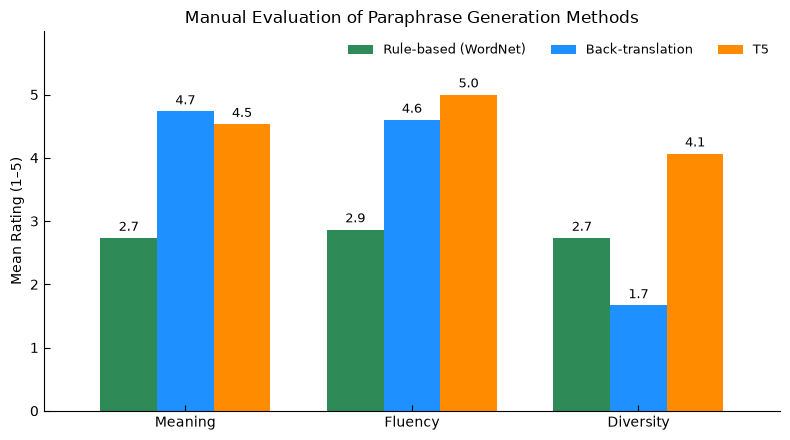

In [12]:
sheet = pd.read_csv(sheet_path, encoding="utf-8-sig")

sheet[RATING_COLS] = sheet[RATING_COLS].apply(pd.to_numeric, errors="coerce")

# Check if any ratings are present
total_ratings = sheet[RATING_COLS].notna().sum().sum()

if total_ratings == 0:

    print("No ratings yet. Fill in the three rating columns, save the CSV, then re-run this cell.")

else:

    manual = sheet.groupby("method")[RATING_COLS].mean()
    manual = manual.reindex(METHODS)

    pairs_rated = sheet.groupby("method")[RATING_COLS[0]].count()
    pairs_rated = pairs_rated.reindex(METHODS)

    manual.insert(0, "pairs_rated", pairs_rated)

    manual.to_csv(f"{OUT}/manual_review_results.csv")
    display(manual.round(2))

    fig, ax = plt.subplots(figsize=(8, 4.5))

    manual[RATING_COLS].T.plot(kind="bar", ax=ax, color=COLORS, width=0.75, rot=0)

    for bars in ax.containers:
        ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=9)

    ax.set_xticklabels(["Meaning", "Fluency", "Diversity"])
    ax.set_xlabel("")
    ax.set_ylabel("Mean Rating (1–5)")
    ax.set_title("Manual Evaluation of Paraphrase Generation Methods")

    ax.set_ylim(0, 6.0)
    ax.set_yticks([0, 1, 2, 3, 4, 5])

    style(ax)

    ax.legend(loc="upper right", frameon=False, title="", ncol=3, fontsize=9)

    save_fig("fig_manual_review")
    plt.show()
    plt.close(fig)